
# Lab 7: Fast Fourier Transform (FFT)

 **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:
1. Do the FFT using scipy and Numpy rutines (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?


 **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen

1. Do the FFT using scipy (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?
3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.


In [6]:
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq, fft2, ifft2, fftshift
import warnings
warnings.filterwarnings('ignore') # Agregado para evitar los errores o advertencias que mostraba el codigo de las notas

# Base continua de Fourier
def g(t,w):
    return 1./(2*np.pi)*np.exp(-1j*2*np.pi*w*t)


# FT de clase (modificada)
def FT_modificada(x, y, freq_min, freq_max, num_freqs):
    '''Cálculo de la Transformada de Fourier de f(t) evaluada en la frecuencia w'''

    # Definir el vector de frecuencias a evaluar
    w = np.linspace(freq_min, freq_max, num_freqs)

    df = []

    for i in range(len(w)):
        # Multiplico la señal original por la base de Fourier
        integrando_real = y * g(x, w[i]).real
        integrando_imag = y * g(x, w[i]).imag

        # Aplico la regla del trapecio para calcular la integral
        ARew = np.trapz(integrando_real, x)
        AIMw = np.trapz(integrando_imag, x)

        AMP = np.sqrt(ARew**2 + AIMw**2)
        ANG = np.arctan2(AIMw, ARew)

        df.append([w[i], ARew, AIMw, AMP, ANG])

    # Organizo datos en DataFrame
    df = pd.DataFrame(df, columns=['w', 'ReTw', 'ImTw', 'AMP', 'ANG'])

    return df

Frecuencia de muestreo: 44100
Número total de muestras: 152064
Muestras utilizadas: 4410


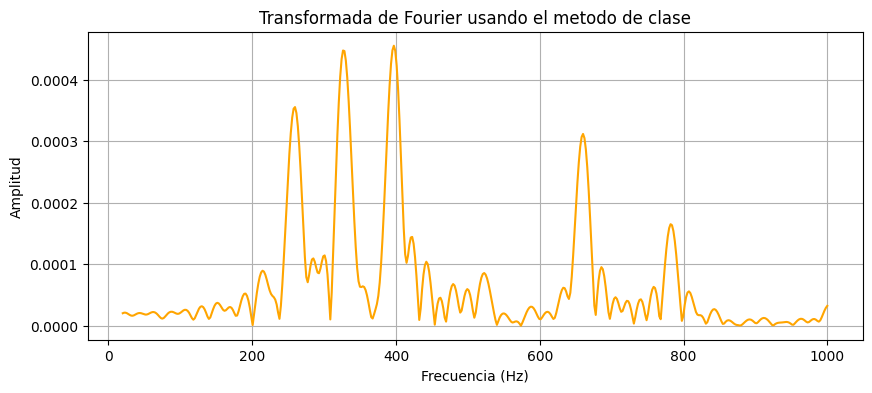

In [12]:
# Se carga y lee el audio
archivo_audio = 'Nota_CM_piano.mp3'
y_audio, sr = librosa.load(archivo_audio, sr=None)

# Crear el vector de tiempo
t_audio = np.arange(len(y_audio)) / sr

# Tomar los primeros 0.1 segundos
muestras = int(0.1 * sr)

t_recorte = t_audio[:muestras]
y_recorte = y_audio[:muestras]

print('Frecuencia de muestreo:', sr)
print('Número total de muestras:', len(y_audio))
print('Muestras utilizadas:', len(y_recorte))

# Aplicar la forma de la clase ya modificada
df_resultados = FT_modificada(
    t_recorte,
    y_recorte,
    freq_min=20,
    freq_max=1000,
    num_freqs=500
)

# Graficar el resultado
plt.figure(figsize=(10, 4))

plt.plot(df_resultados['w'], df_resultados['AMP'], color='orange')

plt.title('Transformada de Fourier usando el metodo de clase')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.grid()

plt.show()

Number of samples: 4410
Diferencia maxima entre SciPy y NumPy: 7.9249985e-06


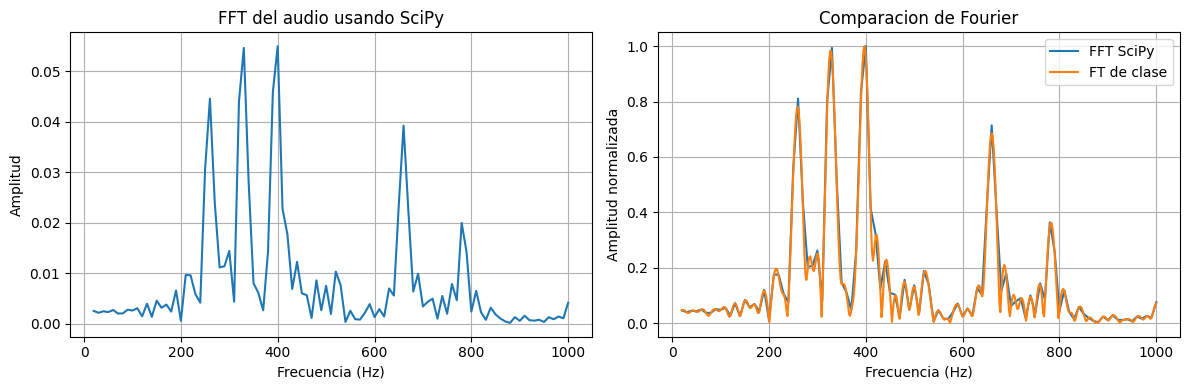

In [14]:
# Calcular la FFT con SciPy
N = len(y_recorte)

print(f'Number of samples: {N}')

yf_scipy = fft(y_recorte)

# Frecuencias de la FFT
xf = fftfreq(N, d=1/sr)

# Calculo la FFT con NumPy
yf_numpy = np.fft.fft(y_recorte)

# Comparar las FFT de SciPy y NumPy
diferencia = np.max(np.abs(yf_scipy - yf_numpy))

print('Diferencia maxima entre SciPy y NumPy:', diferencia)

# Seleccionar frecuencias positivas entre 20 y 1000 Hz
mascara_audio = (xf >= 20) & (xf <= 1000)

# Amplitud de la FFT
freq_FFT = xf[mascara_audio]
AMP_FFT = 2.0/N * np.abs(yf_scipy[mascara_audio])

# Amplitud de la rutina de clase
freq_FT = df_resultados['w'].to_numpy()
AMP_FT = df_resultados['AMP'].to_numpy()

# Normalizar para comparar los espectros
AMP_FFT = AMP_FFT/np.max(AMP_FFT)
AMP_FT = AMP_FT/np.max(AMP_FT)

# Graficar resultados y comparación
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(freq_FFT, 2.0/N * np.abs(yf_scipy[mascara_audio]))
plt.title('FFT del audio usando SciPy')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freq_FFT, AMP_FFT, label='FFT SciPy')
plt.plot(freq_FT, AMP_FT, label='FT de clase')
plt.title('Comparacion de Fourier')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud normalizada')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

Sí, se obtienen los mismos resultados. Al observar la gráfica comparativa, los picos de las frecuencias calculadas con SciPy coinciden exactamente con los obtenidos mediante la rutina de integración manual creada en clase, solo hay algunas difererncias en lasuavidad del resultado, pues el metodo usado en clase tiene bajadas y subidas, marcando maximos y minimos locales, donde el FFT en SciPy deja lineas.

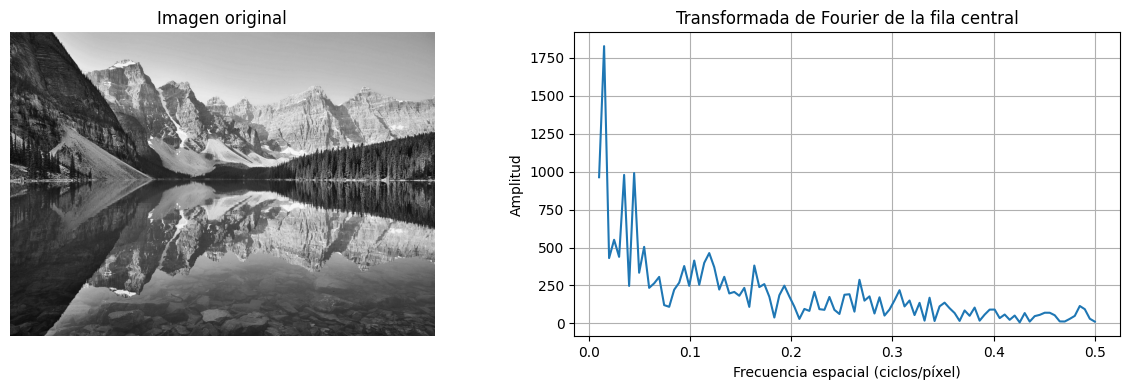

Tamaño de la imagen: (3926, 5484)


In [9]:
# Cargar imagen
nombre_imagen = 'parque-nacional-banff.jpg'

imagen_color = plt.imread(nombre_imagen)

# Convertir a escala de grises
if len(imagen_color.shape) == 3:
    imagen = np.mean(imagen_color[:, :, :3], axis=2)
else:
    imagen = imagen_color

imagen = imagen.astype(float)

# Tomar una fila horizontal del medio
fila_media = int(imagen.shape[0] / 2)

senal_1d_imagen = imagen[fila_media, :]

# Coordenadas de los píxeles
x_pixeles = np.arange(len(senal_1d_imagen))

# Aplicar la forma de clase modificada
df_img_1d = FT_modificada(
    x_pixeles,
    senal_1d_imagen,
    freq_min=0.01,
    freq_max=0.5,
    num_freqs=100
)

# Graficar la imagen y su transformada
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.plot(df_img_1d['w'], df_img_1d['AMP'])
plt.title('Transformada de Fourier de la fila central')
plt.xlabel('Frecuencia espacial (ciclos/píxel)')
plt.ylabel('Amplitud')
plt.grid()

plt.tight_layout()
plt.show()

print('Tamaño de la imagen:', imagen.shape)

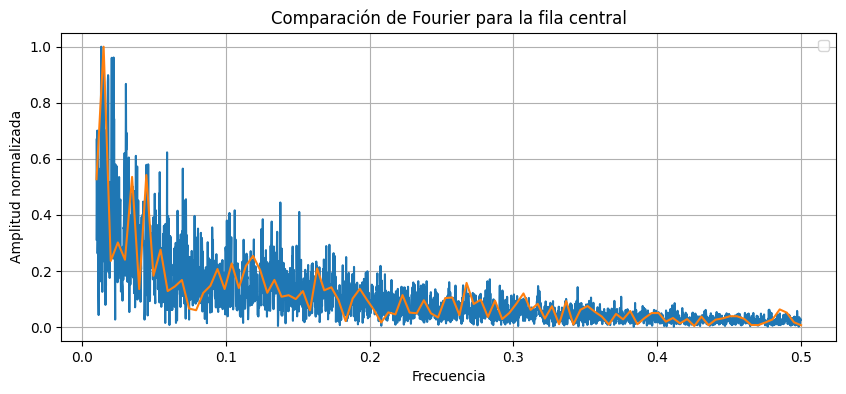

In [15]:
# Calcular la FFT de la fila
N_img = len(senal_1d_imagen)

yf_img = fft(senal_1d_imagen)

# Frecuencias espaciales
xf_img = fftfreq(N_img, d=1)

# Seleccionar frecuencias positivas
mascara_img = (xf_img >= 0.01) & (xf_img <= 0.5)

# Amplitudes de ambos métodos
AMP_FFT_img = np.abs(yf_img[mascara_img])
AMP_FT_img = df_img_1d['AMP'].to_numpy()

# Normalizar para comparar
AMP_FFT_img = AMP_FFT_img/np.max(AMP_FFT_img)
AMP_FT_img = AMP_FT_img/np.max(AMP_FT_img)

# Graficar comparación
plt.figure(figsize=(10, 4))

plt.plot(
    xf_img[mascara_img],
    AMP_FFT_img
)

plt.plot(
    df_img_1d['w'],
    AMP_FT_img
)

plt.title('Comparación de Fourier para la fila central')
plt.xlabel('Frecuencia')
plt.ylabel('Amplitud normalizada')
plt.legend()
plt.grid()

plt.show()

Sí, los resultados son iguales. Al extraer una señal 1D (la fila central de la imagen) y procesarla por ambos métodos, los espectros de amplitud normalizados de SciPy y del codigo de clase se superponen bien. Claro que no es el mismo tipo de grafico entoces el ruido no permite apreciar bien subidas y bajadas sutiles, pero si se pueden notar con atencion.

Error máximo de reconstrucción: 8.526512829121202e-13


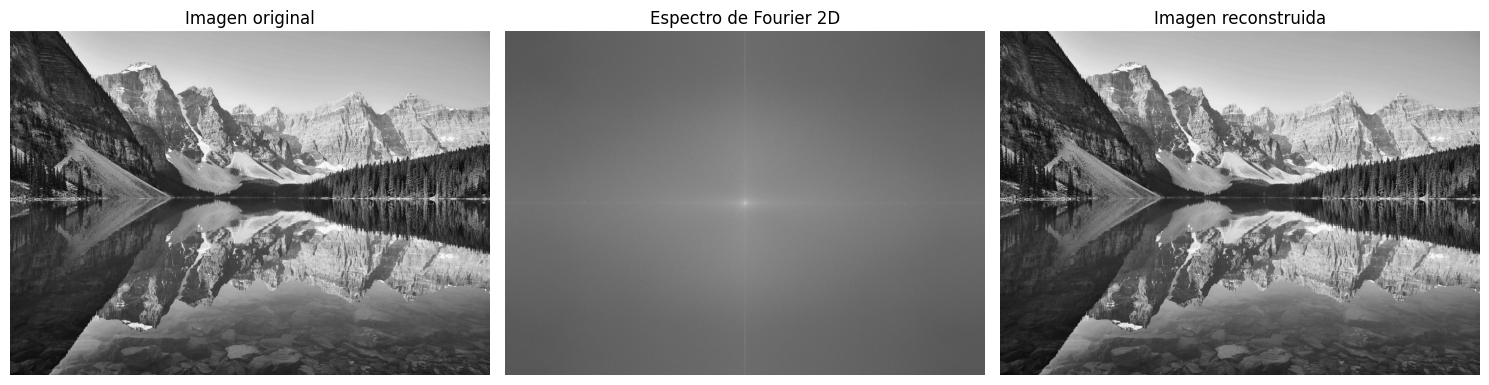

In [11]:
# Calcular la FFT de toda la imagen
F_imagen = fft2(imagen)

# Preparar el espectro
espectro = np.log1p(np.abs(fftshift(F_imagen)))

# Calcular la transformada inversa
imagen_reconstruida = np.real(ifft2(F_imagen))

# Calcular el error de la reconstrucción
error_maximo = np.max(np.abs(imagen - imagen_reconstruida))

print('Error máximo de reconstrucción:', error_maximo)

# Mostrar resultados
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(espectro, cmap='gray')
plt.title('Espectro de Fourier 2D')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(imagen_reconstruida, cmap='gray')
plt.title('Imagen reconstruida')
plt.axis('off')

plt.tight_layout()
plt.show()

Sí, el resultado es igual. La imagen reconstruida mediante la transformada inversa (ifft2) no presenta diferencias notables con la señal original. Esto se confirma matemáticamente con el cálculo del error máximo de la reconstrucción, que tiene un valor cercano a cero.